In [35]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/roqaia1ai/my-test-data/OIP (1).jpg
/kaggle/input/datasets/roqaia1ai/my-test-data/OIP.jpg
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/sample_submission.csv
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/test.zip


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from pandas.core.arrays import categorical
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
import zipfile
from catboost import CatBoostClassifier
from google.colab import files
import lightgbm as lgb
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
# الرقم 3 ده بيقول للبرنامج: "لو سمحت، متطلعليش أي رسائل تحذيرية، طلعلي بس لو فيه مصيبة (Error) حقيقية".
import tensorflow as tf
from tensorflow.keras import layers, models
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense, Activation, BatchNormalization
from keras.layers import Input
# السطر الجديد اللي هيحل الأزمة:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications import MobileNetV2

In [37]:
# جميع الملفات الموجودة في /kaggle/input
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/roqaia1ai/my-test-data/OIP (1).jpg
/kaggle/input/datasets/roqaia1ai/my-test-data/OIP.jpg
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/sample_submission.csv
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/test.zip


In [38]:
with zipfile.ZipFile("/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip","r")as zip_ref:
  zip_ref.extractall()
with zipfile.ZipFile("/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/test.zip","r")as zip_ref2:
  zip_ref2.extractall()
# بنجيب لستة بأسماء الصور اللي اتفكت في الفولدر
train_images = os.listdir('/kaggle/working/train')
test_images = os.listdir('/kaggle/working/test')

print(f"عدد صور التدريب: {len(train_images)}")
print(f"مثال لاسم صورة: {train_images[0]}")
# في مسابقة القطط والكلاب عملنا فك ضغط وبعدين لستة بالأسماء"

عدد صور التدريب: 25000
مثال لاسم صورة: cat.12029.jpg


In [39]:
path1='/kaggle/working/train/'# تأكدي من وجود الـ / في الآخر
path2='/kaggle/working/test/'
# كل اسم الصورة في ليست التدريب حط المسار قبلها ثم نحطها جوه ليست جديده 
# كلمة items() دي بنستخدمها مع الـ Dictionary (اللي بيكون مفتاح وقيمة زي {'name': 'Ahmed'}).

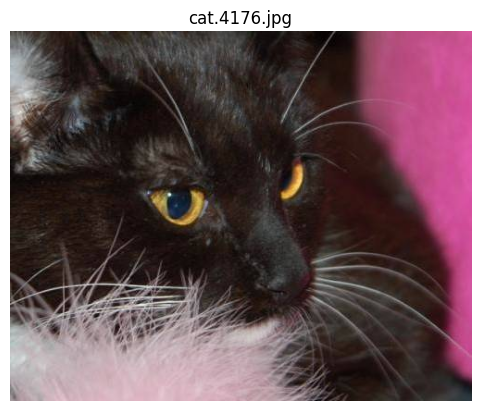

In [40]:
A= path1 + train_images[4]
# 2. اقرئي الصورة
img = mpimg.imread(A)

# 3. اعرضيها
plt.imshow(img)
plt.title(train_images[4]) # عشان يكتب اسم الصورة فوقها (مثلاً cat.0.jpg)
plt.axis('off') # سطر اختياري بيخفي الأرقام اللي على الجناب (الإحداثيات)
plt.show()

In [41]:
categories=[]
for y in train_images:
    prefix=y.split('.')[0]
    if prefix=="dog":
       categories.append(1)
    else :
     categories.append(0)

In [42]:
# 2. تحويل البيانات لجدول (DataFrame) عشان التعامل يبقى أسهل
df = pd.DataFrame({
    'filename': train_images,
    'category': categories
})

# 3. حولي الأرقام لنصوص (ضروري للـ Generator اللي هنستخدمه بعدين)
df['category'] = df['category'].replace({0: 'cat', 1: 'dog'})

print(df.head()) # هيعرض لك أول 5 صفوف تتأكدي إن كله تمام

        filename category
0  cat.12029.jpg      cat
1   dog.1741.jpg      dog
2   dog.8469.jpg      dog
3    cat.752.jpg      cat
4   cat.4176.jpg      cat


<Axes: xlabel='category'>

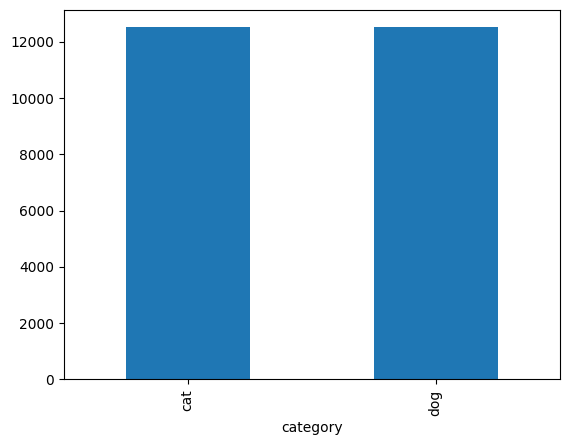

In [43]:
df['category'].value_counts().plot.bar()

In [44]:
# 1. بنجيب "المخ" الجاهز (متدرب على مليون صورة في مسابقة ImageNet)
# بنقوله include_top=False عشان نشيل "الرأس" بتاعته ونركب رأس لقططنا وكلابنا
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
# weights='imagenet': بنقول لبايثون: "يا بايثون، حمل لي الموديل ده وهو متعلم وجاهز من صور مسابقة ImageNet (اللي فيها مليون صورة)". يعني الموديل مش جاي "أبيض"، ده جاي "خبير" بيعرف الأشكال والألوان.
# include_top=False: دي أهم حتة! الموديل الأصلي آخره طبقة بتصنف 1000 حاجة. إحنا بنقوله "شيل الراس (الـ Top) دي"، لأننا مش عايزين الـ 1000 حاجة، إحنا هنركب له "راس" جديدة خاصة بالقطط والكلاب بس.
# 2. بنجمد "المخ" ده عشان ميتغيرش وهو بيتدرب (Freeze)
base_model.trainable = False
# 1. بناء الهيكل
model = Sequential()
model.add(Input(shape=(128, 128, 3)))

# 2. طبقات التزييف (Data Augmentation) - دي اللي بتحميكي من الصور المخادعة
model.add(layers.RandomFlip("horizontal"))
model.add(layers.RandomRotation(0.1))
model.add(layers.RandomZoom(0.1))

# 3. إضافة "المخ الجاهز" (الكنز بتاعنا)
model.add(base_model) 

# 4. تحويل المخرجات لشكل بسيط (بدل Flatten)
model.add(layers.GlobalAveragePooling2D())

# 5. طبقة حماية (Dropout) عشان ميبقاش "دحيح" زيادة عن اللزوم
model.add(layers.Dropout(0.5))

# 6. طبقة القرار النهائي (قطة 0 ولا كلب 1)
model.add(layers.Dense(1, activation='sigmoid'))

# 7. التجميع (Compile)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# الـ Flatten: هو إنك تجمعي كل الحروف اللي في الـ 100 صفحة جنب بعض وتديهم للمدير يقرأهم حرف حرف. (مجهود ضخم ولخبطة).

# الـ GAP: هو إنك تقرئي كل صفحة وتكتبي عنها "سطر واحد" ملخص، وتديله الـ 100 سطر دول. (خلاصة مفيدة وقرار أسرع)


# ده الكود الاصلي اللي المفروض يتعمل في اي موديل صور من الصفر يعني مع تدريب كل الطبقات الكود القادم
# model = Sequential()

# # 1. تحديد حجم الصورة (المدخلات)
# model.add(Input(shape=(128, 128, 3)))

# # 2. التزييف الذكي (الدرع ضد الحفظ)
# model.add(layers.RandomFlip("horizontal"))
# model.add(layers.RandomRotation(0.1))
# model.add(layers.RandomZoom(0.1))

# # 3. طبقات الـ Convolution (استخراج الملامح)
# model.add(Conv2D(32, (3, 3), activation='relu'))
# model.add(BatchNormalization())
# model.add(MaxPooling2D(pool_size=(2, 2)))
# model.add(Dropout(0.25))

# model.add(Conv2D(64, (3, 3), activation='relu'))
# model.add(BatchNormalization())
# model.add(MaxPooling2D(pool_size=(2, 2)))
# model.add(Dropout(0.25))

# # 4. تحويل البيانات واتخاذ القرار
# model.add(Flatten())
# model.add(Dense(512, activation='relu'))
# model.add(BatchNormalization())
# model.add(Dropout(0.5)) 

# # 5. الطبقة الأخيرة والقرار النهائي
# model.add(Dense(1, activation='sigmoid'))
# Dense(1): يعني "طبقة فيها عصب واحد (Neuron)". ليه واحد؟ لأننا بنسأل سؤال إجابته (أيوة أو لأ) - (0 أو 1).

# activation='sigmoid': دي وظيفتها تحول أي رقم طالع من الموديل لرقم بين (0 و 1).

# لو طلع 0.9 يبقى احتمال كبير "كلب".

# لو طلع 0.1 يبقى احتمال كبير "قطة"
# # 6. التجميع (الـ Compile) مع التصحيحات
# model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [45]:
# 1. بنجهز الآلة ونقولها اقسمي الصور (20% للامتحان)
train_datagen = ImageDataGenerator(
    rescale=1./255,           # دي عشان نخلي الألوان بين 0 و 1 (مهمة للموديل)
    validation_split=0.20     # <--- دي نسبة التقسيم
)
# 2. دلوقتي بنقول للآلة "اسحبي الصور من الجدول"
train_generator = train_datagen.flow_from_dataframe(
    df,                               # الجدول (الخريطة)
    "/kaggle/working/train/",         # <--- ده مكان الصور اللي كنتِ بتسألي عليه!
    x_col='filename',                 # اسم العمود اللي فيه أسماء الصور
    y_col='category',                 # اسم العمود اللي فيه النوع
    target_size=(128, 128),           # الحجم اللي اتفقنا عليه
    class_mode='binary',         # عشان عندنا نوعين (قطة وكلب)
    batch_size=32,                    # ياخد 32 صورة في كل لفة
    subset='training'                 # <--- دي "مجموعة المذاكرة"
)
# # ليه ده حصل؟ (عشان تبقي فاهمة):
# Keras و TensorFlow زي التوأم، بس حالياً Keras بقت مكتبة مستقلة بتشتغل مع كذا محرك.
# النسخة اللي متسطبة على كاجل (3.12) ساعات بتطلب إننا ننده للـ ImageDataGenerator من تحت مظلة tensorflow مباشرة عشان تضمن إنها تلاقيها.

Found 20000 validated image filenames belonging to 2 classes.


In [46]:

validation_generator = train_datagen.flow_from_dataframe(
    df,                               # الجدول (الخريطة)
    "/kaggle/working/train/",         # <--- ده مكان الصور اللي كنتِ بتسألي عليه!
    x_col='filename',                 # اسم العمود اللي فيه أسماء الصور
    y_col='category',                 # اسم العمود اللي فيه النوع
    target_size=(128, 128),           # الحجم اللي اتفقنا عليه
    class_mode='binary',         # عشان عندنا نوعين (قطة وكلب)
    batch_size=32,                    # ياخد 32 صورة في كل لفة
    subset='validation'                 # <--- دي "مجموعة الامتحان"
)
# لما بنخلي class_mode='binary'، الداتا بتبطل تبعت [1, 0] و [0, 1]، وبتبدأ تبعت رقم واحد بس 0 أو 1. كدة الموديل هيفرح جداً لأن الـ Output بتاعه (اللي هو 1) بقى قد الـ Target اللي جاي له (اللي هو 1).
# لما بنعمل كده، الـ Generator بيفهم إنه مش محتاج يبعت علامتين، هيبعت رقم واحد بس (0 أو 1). وكده الموديل هيفرح لأن "مقاس" البيانات اللي جاية له بقى قد "مقاس" المخرج اللي هو بيطلعه

Found 5000 validated image filenames belonging to 2 classes.


In [47]:
# دي "فرامل الطوارئ" الذكية
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', # راقب غلطات الامتحان
    factor=0.2,         # لما تفرمل، قلل السرعة لـ 20% من قيمتها
    patience=2,         # اصبر حصتين، لو مفيش تحسن.. فرمل!
    min_lr=0.00001      # أقل سرعة ممكن توصل لها
)

In [48]:
# 3. ثالثاً: نطلق صافرة البداية (الـ fit)
history = model.fit(
    train_generator,           # الوجبة الرئيسية
    epochs=20,
    validation_data=validation_generator,
    steps_per_epoch=len(train_generator), # أحسن نستخدم len عشان ميتلخبطش
    validation_steps=len(validation_generator),
    callbacks=[reduce_lr]      # ضيفنا الفرامل هنا
)
# الـ Error اللي طلع لك ده علّمك إن الـ fit لازم تبدأ بـ Data.
# الترتيب المنطقي: بايثون لازم "يشوف" الـ validation_generator والـ reduce_lr ويتعرف عليهم الأول قبل ما تقولي له "استخدمهم في التدريب".
# الـ Steps: بدل ما نكتب أرقام يدوية (زي 20000 // 32)، استخدام len(generator) أضمن عشان لو عدد الصور اتغير، الكود ميبوظش.

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.8332 - loss: 0.3620 - val_accuracy: 0.9632 - val_loss: 0.0980 - learning_rate: 0.0010
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - accuracy: 0.9188 - loss: 0.1933 - val_accuracy: 0.9662 - val_loss: 0.0932 - learning_rate: 0.0010
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 55ms/step - accuracy: 0.9240 - loss: 0.1862 - val_accuracy: 0.9686 - val_loss: 0.0865 - learning_rate: 0.0010
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 55ms/step - accuracy: 0.9258 - loss: 0.1778 - val_accuracy: 0.9680 - val_loss: 0.0855 - learning_rate: 0.0010
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - accuracy: 0.9286 - loss: 0.1772 - val_accuracy: 0.9642 - val_loss: 0.0943 - learning_rate: 0.0010
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 55ms/step - accuracy: 0.9278 - loss: 0.1744 - val_accuracy: 0.9658 - val_loss: 0.0941 - learning_rate: 0.0010
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 55ms/step - accuracy: 0.9270 - loss: 0.1780

In [49]:
model.save('model.h5')
# لو الموديل مش بيتحسن أصلاً: (زودي طبقات، أو زودي عدد الخلايا).

# لو الموديل بيحفظ (زي حالتنا): (ضيفي Dropout، أو قللي عدد الخلايا، أو استخدمي Data Augmentation).

# لو الموديل بطيء: (استخدمي GPU، أو صغري حجم الصور شوية)

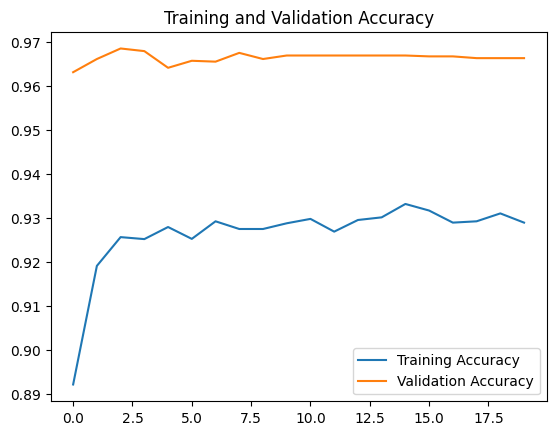

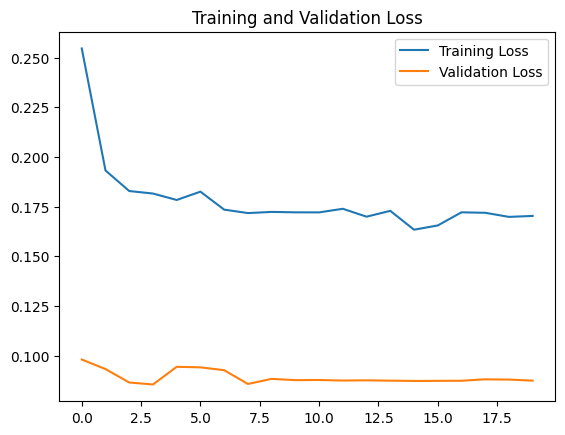

In [50]:
# 1. رسم الدقة (Accuracy)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# 2. رسم الخسارة (Loss)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()
# حصل معايا overfittingفهنعمل  Dropout في الطبقات الأخيرة (الـ Dense)ده هيساعد الموديل يقلل "الحفظ
# نجرب الـ Data Augmentation عشان نخليه يشوف صور أكتر بوضعيات مختلفة

In [ ]:
def predict_my_image(img_path):
    # 1. تحميل الصورة وتصغيرها لنفس الحجم اللي الموديل اتدرب عليه (128x128)
    img = image.load_img(img_path, target_size=(128, 128))
    
    # 2. تحويل الصورة لمصفوفة أرقام (Array)
    img_array = image.img_to_array(img)
    
    # 3. تطبيع الأرقام (نفس اللي عملناه في التدريب / 255)
    img_array = img_array / 255.0
    
    # 4. إضافة بُعد إضافي (عشان الموديل متعود يستلم "دفعة" صور مش صورة واحدة)
    img_array = np.expand_dims(img_array, axis=0)
    
    # 5. اللحظة الحاسمة.. الموديل يتوقع!
    prediction = model.predict(img_array)
    # 6. عرض الصورة والنتيجة
    plt.imshow(img)
    plt.axis('off')
    
    if prediction[0] > 0.5:
        plt.title(f"I'm {prediction[0][0]*100:.2f}% sure this is a DOG! 🐶")
    else:
        plt.title(f"I'm {(1-prediction[0][0])*100:.2f}% sure this is a CAT! 🐱")
    plt.show()
my_image_path1 = "/kaggle/input/datasets/roqaia1ai/my-test-data/OIP.jpg"
A=predict_my_image(my_image_path1 )
print(A)

my_image_path2 = "/kaggle/input/datasets/roqaia1ai/my-test-data/OIP (1).jpg"
B=predict_my_image(my_image_path2 )
print(B)

In [53]:
# 1. نجيب أسامي كل الصور اللي في مجلد الـ test
test_images = os.listdir('/kaggle/working/test')
test_df = pd.DataFrame({
    'id': test_images
})

# 2. نجهز "مولد صور الاختبار" (Test Generator)
# لاحظي هنا class_mode=None لأننا معندناش إجابات أصلاً!
test_gen = train_datagen.flow_from_dataframe(
    test_df, 
    '/kaggle/working/test', 
    x_col='id',
    y_col=None,
    class_mode=None,# احنا هنا قولنا كده لان مينفعش نقوله نوع الكلاس لازم هو اللي يقولي نوعه لما يكتشفه
    target_size=(128, 128),
    batch_size=32,
    shuffle=False # لازم False عشان الترتيب ميبوظش!
)
# 3. نطلب من الموديل يتوقع الـ 12,500 صورة مرة واحدة

Found 12500 validated image filenames.


In [55]:
# 1. نجيب أسامي الصور اللي الموديل اتوقعها فعلاً من الـ Generator
# ده بيضمن إن الطول يكون متساوي 100%
test_gen.reset() # "زودي" السطر ده قبل الـ predict عشان يبدأ من صورة رقم 1
predictions = model.predict(test_gen)
actual_filenames = test_gen.filenames
# 2. نتأكد إن طول التوقعات هو نفسه طول الأسامي
predicted_values = predictions.flatten()

print(f"عدد الصور: {len(actual_filenames)}")
print(f"عدد التوقعات: {len(predicted_values)}")

# 3. نكريت الـ DataFrame وإحنا مطمنين
submission_df = pd.DataFrame({
    'id': [name.split('.')[0] for name in actual_filenames],
    'label': predicted_values
})
# 4. حفظ الملف
submission_df.to_csv('submission.csv', index=False)
print("تم بنجاح! ملف submission.csv جاهز للإقلاع 🚀")

391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step
عدد الصور: 12500
عدد التوقعات: 12500
تم بنجاح! ملف submission.csv جاهز للإقلاع 🚀
